# STAT3612 Tutorial 10 — Introduction to PyTorch

**STAT3612: Statistical Machine Learning (Fall 2026, HKU)**  
**Instructor / TA:** Yinghao Zhu

This companion notebook covers all hands-on code from **Tutorial 10**:
1. **Part 1 — PyTorch Tensors & Shape Manipulation:**
   - Creating tensors (`torch.tensor`, `torch.zeros`, `torch.randn`, `torch.zeros_like`) & checking `.shape`, `.dtype`, `.device`, `.requires_grad`
   - Device-agnostic programming (`cpu` / `cuda`) & the NumPy zero-copy bridge (`torch.from_numpy`, `.detach().cpu().numpy()`)
   - Elementwise Hadamard product (`*`) vs. matrix multiplication (`@` / `torch.matmul`) & batched 3D contractions
   - Reductions along `dim=0` vs. `dim=1` and `keepdim=True`
   - Reshaping (`reshape` vs. `view`), `permute`, `squeeze`, `unsqueeze`, and self-documenting rearrangement with `einops.rearrange`
2. **Part 2 — Computational Graphs & Automatic Differentiation (`autograd`):**
   - Forward & backward propagation with `requires_grad=True` and `.backward()`
   - Vector-Jacobian product for non-scalar outputs
   - Why `optimizer.zero_grad()` is mandatory (gradient accumulation)
   - Controlling gradient tracking during evaluation with `model.eval()` and `torch.no_grad()`
3. **Part 3 — Building & Training Neural Networks (`nn.Module`, MLP & CNN):**
   - Wrapping datasets in `TensorDataset` / custom `Dataset` and `DataLoader`
   - Visualizing activation functions (`Sigmoid`, `Tanh`, `ReLU`, `GELU`) and their derivatives
   - Visualizing 2D decision boundaries: `nn.Linear(2, 1)` vs. 2-layer `ReLU` MLP on `make_moons`
   - Defining an `MLPClassifier(nn.Module)` and comparing `SGD`, `SGD + Momentum`, and `Adam`
   - Upgrading from a flat MLP to a 2D Convolutional Neural Network (`LeNet` with `nn.Conv2d` + `nn.MaxPool2d`)
   - Binary classification with `BCEWithLogitsLoss` and saving/loading model checkpoints via `state_dict()`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from einops import rearrange
from sklearn.datasets import load_breast_cancer, load_digits, make_moons
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
import xgboost as xgb

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | Active device: {device}")

PyTorch 2.14.1+cpu | Active device: cpu


---
## Part 1: PyTorch Tensors & Shape Manipulation

### 1.1 Creating Tensors & Checking Core Attributes

In [2]:
a = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
z = torch.zeros((2, 3), dtype=torch.float32)
r = torch.randn((2, 3))
like_a = torch.ones_like(a)

print("Tensor a:\n", a)
print(f"shape={a.shape} | dtype={a.dtype} | device={a.device} | requires_grad={a.requires_grad}")

Tensor a:
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
shape=torch.Size([2, 3]) | dtype=torch.float32 | device=cpu | requires_grad=False


### 1.2 NumPy Zero-Copy Bridge & Safe Conversion

In [3]:
np_arr = np.array([[10.0, 20.0], [30.0, 40.0]], dtype=np.float32)
t_from_np = torch.from_numpy(np_arr)
np_arr[0, 0] = 99.0  # mutating NumPy array also updates CPU tensor!
print("Shared-memory tensor after NumPy mutation:\n", t_from_np)

# Safe conversion back to NumPy (works even if tensor is on GPU or requires_grad=True)
t_grad = torch.randn(2, 2, device=device, requires_grad=True)
safe_np = t_grad.detach().cpu().numpy()
print("Safely detached NumPy shape:", safe_np.shape)

Shared-memory tensor after NumPy mutation:
 tensor([[99., 20.],
        [30., 40.]])
Safely detached NumPy shape: (2, 2)


### 1.3 Elementwise Product (`*`) vs. Matrix Multiplication (`@`) & Reductions Along `dim`

In [4]:
A = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])  # (2, 3)
B = torch.ones((2, 3)) * 2.0                           # (2, 3)
C = torch.arange(12, dtype=torch.float32).reshape(3, 4) # (3, 4)

print("Elementwise A * B (shape", (A * B).shape, "):\n", A * B)
print("Matrix multiply A @ C (shape", (A @ C).shape, "):\n", A @ C)

# Batched 3D matrix multiplication: (B, T, d_k) @ (B, d_k, T) -> (B, T, T)
Q = torch.randn(8, 5, 16)
K_t = torch.randn(8, 16, 5)
print("Batched 3D Q @ K_t shape:", (Q @ K_t).shape)

Elementwise A * B (shape torch.Size([2, 3]) ):
 tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
Matrix multiply A @ C (shape torch.Size([2, 4]) ):
 tensor([[ 32.,  38.,  44.,  50.],
        [ 68.,  83.,  98., 113.]])
Batched 3D Q @ K_t shape: torch.Size([8, 5, 5])


In [5]:
x = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print("Original x (2, 3):\n", x)
print("x.sum(dim=0) [collapse rows -> (3,)]:", x.sum(dim=0))
print("x.sum(dim=1) [collapse cols -> (2,)]:", x.sum(dim=1))
print("x.mean(dim=1, keepdim=True) [shape (2, 1)]:\n", x.mean(dim=1, keepdim=True))

Original x (2, 3):
 tensor([[1., 2., 3.],
        [4., 5., 6.]])
x.sum(dim=0) [collapse rows -> (3,)]: tensor([5., 7., 9.])
x.sum(dim=1) [collapse cols -> (2,)]: tensor([ 6., 15.])
x.mean(dim=1, keepdim=True) [shape (2, 1)]:
 tensor([[2.],
        [5.]])


### 1.4 Reshaping, `permute`, `squeeze`/`unsqueeze` & `einops.rearrange`

4D batch shape (B, C, H, W): torch.Size([4, 1, 8, 8])
Flattened shape: torch.Size([4, 64]) | Patchified shape: torch.Size([4, 16, 4])


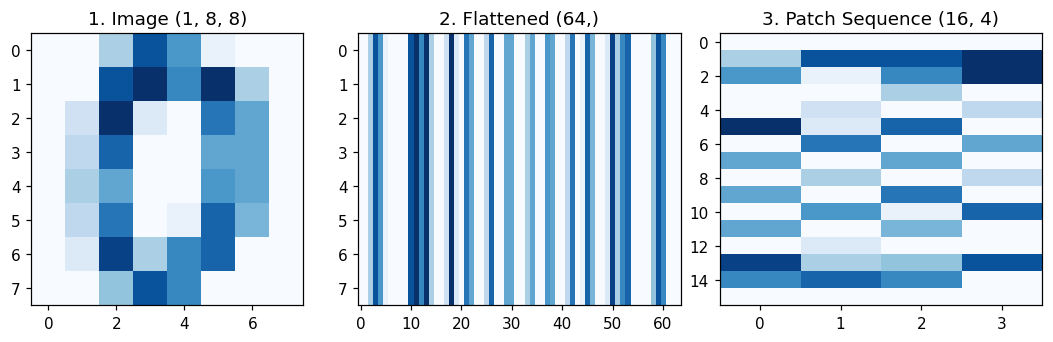

In [6]:
digits = load_digits()
imgs = torch.tensor(digits.images[:4], dtype=torch.float32).unsqueeze(1)  # (b=4, c=1, h=8, w=8)
print("4D batch shape (B, C, H, W):", imgs.shape)

# 1. Flatten spatial axes for an MLP
flat = rearrange(imgs, "b c h w -> b (c h w)")
# 2. Split each 8x8 image into sixteen 2x2 patches (Vision Transformer style)
patches = rearrange(imgs, "b c (h p1) (w p2) -> b (h w) (p1 p2 c)", p1=2, p2=2)
print("Flattened shape:", flat.shape, "| Patchified shape:", patches.shape)

fig, axs = plt.subplots(1, 3, figsize=(9.5, 3.0), layout="constrained")
axs[0].imshow(imgs[0, 0].numpy(), cmap="Blues")
axs[0].set_title("1. Image (1, 8, 8)")
axs[1].imshow(np.repeat(flat[0:1].numpy(), 8, axis=0), cmap="Blues", aspect="auto")
axs[1].set_title("2. Flattened (64,)")
axs[2].imshow(patches[0].numpy(), cmap="Blues", aspect="auto")
axs[2].set_title("3. Patch Sequence (16, 4)")
plt.show()

---
## Part 2: Computational Graphs & Automatic Differentiation (`autograd`)

### 2.1 Forward/Backward Propagation & Analytical Verification

In [7]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = (x ** 2 + 3.0 * x).sum()  # dy/dx_i = 2*x_i + 3
y.backward()

print("Input x:           ", x.detach().numpy())
print("Autograd x.grad:   ", x.grad.numpy())
print("Analytical 2*x + 3:", (2.0 * x.detach() + 3.0).numpy())

Input x:            [1. 2. 3.]
Autograd x.grad:    [5. 7. 9.]
Analytical 2*x + 3: [5. 7. 9.]


### 2.2 Critical Pitfall: Why `optimizer.zero_grad()` Is Mandatory

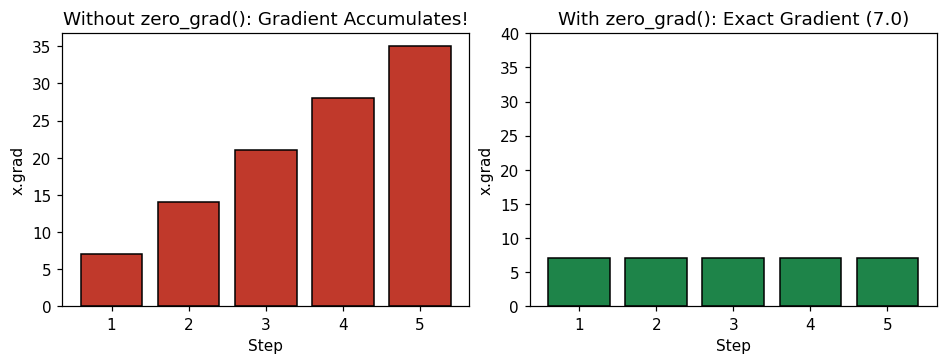

In [8]:
x_acc = torch.tensor([2.0], requires_grad=True)
accum_history, clean_history = [], []

for _ in range(5):
    y_acc = x_acc ** 2 + 3.0 * x_acc
    y_acc.backward()
    accum_history.append(x_acc.grad.item())

x_clean = torch.tensor([2.0], requires_grad=True)
for _ in range(5):
    if x_clean.grad is not None:
        x_clean.grad.zero_()
    y_clean = x_clean ** 2 + 3.0 * x_clean
    y_clean.backward()
    clean_history.append(x_clean.grad.item())

fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.2), layout="constrained")
axs[0].bar(range(1, 6), accum_history, color="#c0392b", edgecolor="k")
axs[0].set_title("Without zero_grad(): Gradient Accumulates!")
axs[0].set_xlabel("Step")
axs[0].set_ylabel("x.grad")
axs[1].bar(range(1, 6), clean_history, color="#1e8449", edgecolor="k")
axs[1].set_title("With zero_grad(): Exact Gradient (7.0)")
axs[1].set_xlabel("Step")
axs[1].set_ylabel("x.grad")
plt.ylim(0, 40)
plt.show()

---
## Part 3: Building & Training Neural Networks in PyTorch

### 3.1 Non-Linear Activation Functions & Their Gradients

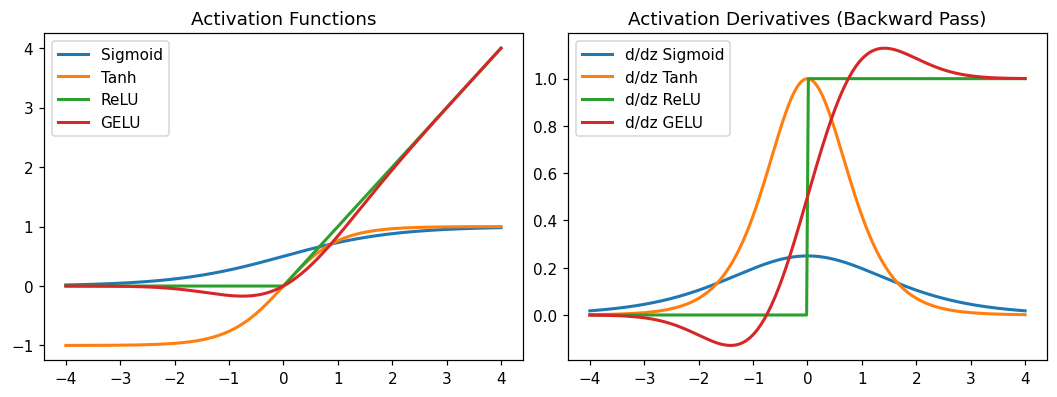

In [9]:
z = torch.linspace(-4.0, 4.0, 250, requires_grad=True)
acts = {
    "Sigmoid": torch.sigmoid(z),
    "Tanh": torch.tanh(z),
    "ReLU": torch.relu(z),
    "GELU": nn.functional.gelu(z),
}

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.5), layout="constrained")
for name, out_t in acts.items():
    axs[0].plot(z.detach().numpy(), out_t.detach().numpy(), lw=2.0, label=name)
    grad_z = torch.autograd.grad(out_t.sum(), z, retain_graph=True)[0]
    axs[1].plot(z.detach().numpy(), grad_z.detach().numpy(), lw=2.0, label=f"d/dz {name}")
axs[0].set_title("Activation Functions")
axs[0].legend()
axs[1].set_title("Activation Derivatives (Backward Pass)")
axs[1].legend()
plt.show()

### 3.2 Visual Proof on `make_moons`: Single Linear Layer vs. 2-Layer `ReLU` MLP

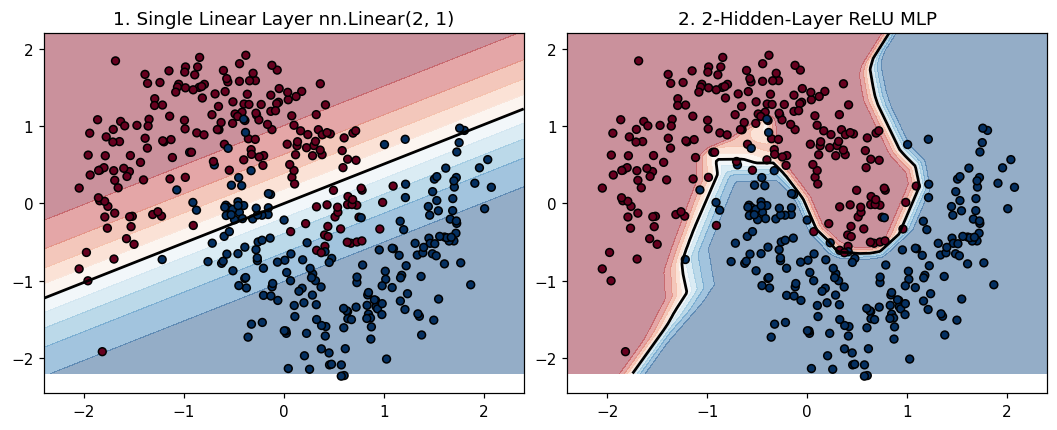

In [10]:
X_m, y_m = make_moons(n_samples=400, noise=0.22, random_state=42)
X_m_std = StandardScaler().fit_transform(X_m).astype(np.float32)
Xm_t = torch.from_numpy(X_m_std)
ym_t = torch.from_numpy(y_m.astype(np.float32)).unsqueeze(1)

torch.manual_seed(42)
lin_net = nn.Linear(2, 1)
opt_l = torch.optim.Adam(lin_net.parameters(), lr=0.05)
for _ in range(150):
    opt_l.zero_grad()
    nn.functional.binary_cross_entropy_with_logits(lin_net(Xm_t), ym_t).backward()
    opt_l.step()

torch.manual_seed(42)
deep_net = nn.Sequential(nn.Linear(2, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))
opt_d = torch.optim.Adam(deep_net.parameters(), lr=0.03)
for _ in range(200):
    opt_d.zero_grad()
    nn.functional.binary_cross_entropy_with_logits(deep_net(Xm_t), ym_t).backward()
    opt_d.step()

xx, yy = np.meshgrid(np.linspace(-2.4, 2.4, 150), np.linspace(-2.2, 2.2, 150))
grid_t = torch.from_numpy(np.c_[xx.ravel(), yy.ravel()].astype(np.float32))
with torch.no_grad():
    p_lin = torch.sigmoid(lin_net(grid_t)).reshape(xx.shape).numpy()
    p_deep = torch.sigmoid(deep_net(grid_t)).reshape(xx.shape).numpy()

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.8), layout="constrained")
for ax, p_grid, title in zip(axs, [p_lin, p_deep], ["1. Single Linear Layer nn.Linear(2, 1)", "2. 2-Hidden-Layer ReLU MLP"]):
    ax.contourf(xx, yy, p_grid, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.45)
    ax.contour(xx, yy, p_grid, levels=[0.5], colors=["k"], linewidths=1.8)
    ax.scatter(X_m_std[:, 0], X_m_std[:, 1], c=y_m, cmap="RdBu", edgecolors="k", s=26)
    ax.set_title(title)
plt.show()

### 3.3 Custom `Dataset`, `DataLoader` & `MLPClassifier(nn.Module)` on Handwritten Digits

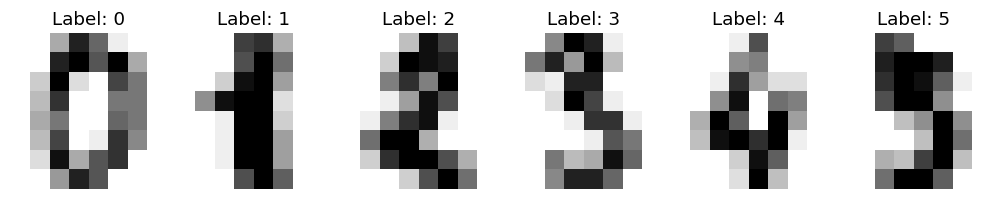

In [11]:
X_d = StandardScaler().fit_transform(digits.data).astype(np.float32)
y_d = digits.target.astype(np.int64)
X_tr, X_te, y_tr, y_te = train_test_split(X_d, y_d, test_size=0.25, stratify=y_d, random_state=42)

class DigitsDataset(Dataset):
    def __init__(self, features, labels):
        self.X = torch.from_numpy(features)
        self.y = torch.from_numpy(labels)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(DigitsDataset(X_tr, y_tr), batch_size=64, shuffle=True)
test_loader = DataLoader(DigitsDataset(X_te, y_te), batch_size=128, shuffle=False)

fig, axs = plt.subplots(1, 6, figsize=(9.0, 1.8), layout="constrained")
for i, ax in enumerate(axs):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")
plt.show()

In [12]:
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=64, hidden_dim=64, num_classes=10, dropout_p=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)

model_demo = MLPClassifier().to(device)
print(model_demo)
print("Total trainable parameters:", sum(p.numel() for p in model_demo.parameters() if p.requires_grad))

MLPClassifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)
Total trainable parameters: 4810


### 3.4 The Canonical 5-Step `train_epoch` & `evaluate` Functions

In [13]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()          # 1. Reset gradients
        logits = model(xb)             # 2. Forward pass
        loss = criterion(logits, yb)   # 3. Compute loss
        loss.backward()                # 4. Backpropagation
        optimizer.step()               # 5. Update weights
        total_loss += loss.item() * yb.size(0)
    return total_loss / len(loader.dataset)


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * yb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n

Final Test Accuracy -> Vanilla SGD: 94.67% | SGD+Momentum: 98.00% | Adam: 97.78%


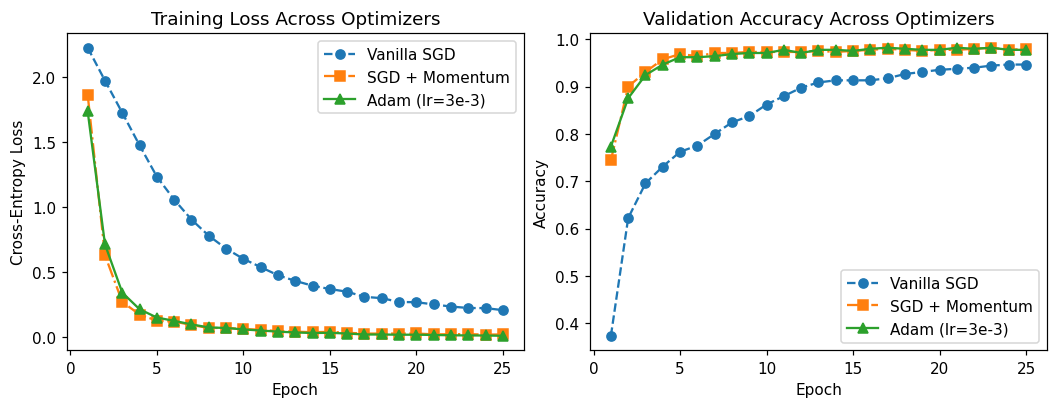

In [14]:
def run_experiment(opt_type="adam", epochs=25):
    torch.manual_seed(42)
    m = MLPClassifier().to(device)
    crit = nn.CrossEntropyLoss()
    if opt_type == "sgd":
        opt = torch.optim.SGD(m.parameters(), lr=0.03)
    elif opt_type == "sgd_mom":
        opt = torch.optim.SGD(m.parameters(), lr=0.03, momentum=0.9)
    else:
        opt = torch.optim.Adam(m.parameters(), lr=3e-3)
    tr_losses, val_losses, val_accs = [], [], []
    for _ in range(epochs):
        tr_losses.append(train_epoch(m, train_loader, crit, opt))
        vl, va = evaluate(m, test_loader, crit)
        val_losses.append(vl)
        val_accs.append(va)
    return m, tr_losses, val_losses, val_accs

_, sgd_tr, sgd_val, sgd_acc = run_experiment("sgd")
_, mom_tr, mom_val, mom_acc = run_experiment("sgd_mom")
mlp_trained, adam_tr, adam_val, adam_acc = run_experiment("adam")
print(f"Final Test Accuracy -> Vanilla SGD: {sgd_acc[-1]*100:.2f}% | SGD+Momentum: {mom_acc[-1]*100:.2f}% | Adam: {adam_acc[-1]*100:.2f}%")

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6), layout="constrained")
ep = np.arange(1, 26)
axs[0].plot(ep, sgd_tr, "o--", label="Vanilla SGD")
axs[0].plot(ep, mom_tr, "s-.", label="SGD + Momentum")
axs[0].plot(ep, adam_tr, "^-", label="Adam (lr=3e-3)")
axs[0].set_title("Training Loss Across Optimizers")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Cross-Entropy Loss")
axs[0].legend()

axs[1].plot(ep, sgd_acc, "o--", label="Vanilla SGD")
axs[1].plot(ep, mom_acc, "s-.", label="SGD + Momentum")
axs[1].plot(ep, adam_acc, "^-", label="Adam (lr=3e-3)")
axs[1].set_title("Validation Accuracy Across Optimizers")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
axs[1].legend()
plt.show()

### 3.5 Upgrading from a Flat MLP to a 2D Convolutional Neural Network (`LeNet`)

In [15]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),  # 8x8 -> 4x4
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, num_classes),
        )

    def forward(self, x):
        # Reshape flat 64D vector back to 2D image (B, 1, 8, 8) if needed
        if x.ndim == 2:
            x = x.reshape(-1, 1, 8, 8)
        return self.classifier(self.features(x))

torch.manual_seed(42)
cnn_model = SmallCNN().to(device)
opt_cnn = torch.optim.Adam(cnn_model.parameters(), lr=3e-3)
crit_cnn = nn.CrossEntropyLoss()
for _ in range(25):
    train_epoch(cnn_model, train_loader, crit_cnn, opt_cnn)
_, cnn_acc = evaluate(cnn_model, test_loader, crit_cnn)
print(f"2D CNN Test Accuracy: {cnn_acc*100:.2f}% (vs. Flat MLP: {adam_acc[-1]*100:.2f}%)")

2D CNN Test Accuracy: 97.78% (vs. Flat MLP: 97.78%)


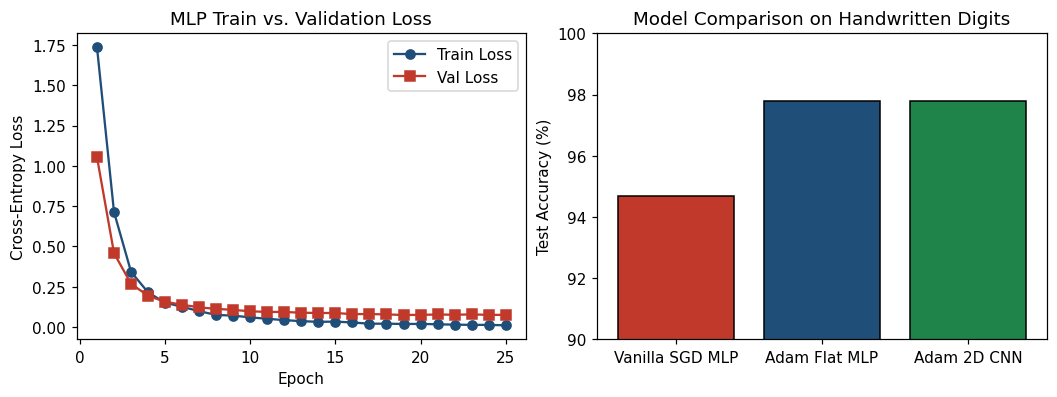

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.5), layout="constrained")
axs[0].plot(ep, adam_tr, "o-", color="#1f4e79", label="Train Loss")
axs[0].plot(ep, adam_val, "s-", color="#c0392b", label="Val Loss")
axs[0].set_title("MLP Train vs. Validation Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Cross-Entropy Loss")
axs[0].legend()

axs[1].bar(["Vanilla SGD MLP", "Adam Flat MLP", "Adam 2D CNN"], [sgd_acc[-1]*100, adam_acc[-1]*100, cnn_acc*100], color=["#c0392b", "#1f4e79", "#1e8449"], edgecolor="k")
axs[1].set_ylim(90, 100)
axs[1].set_ylabel("Test Accuracy (%)")
axs[1].set_title("Model Comparison on Handwritten Digits")
plt.show()

---
## Part 4: Binary Classification (`BCEWithLogitsLoss`) & Saving/Loading Checkpoints (`state_dict`)
Below we train a binary classification MLP with `nn.BCEWithLogitsLoss()` on the 30-feature Wisconsin Breast Cancer benchmark and demonstrate how to save and reload PyTorch model weights via `state_dict()`.

In [17]:
cancer = load_breast_cancer()
X_bc = cancer.data.astype(np.float32)
y_bc = cancer.target.astype(np.float32)
print("Breast Cancer dataset:", X_bc.shape, "| Positive rate:", y_bc.mean().round(3))

Breast Cancer dataset: (569, 30) | Positive rate: 0.627


In [18]:
def train_tabular_mlp(X_tr_s, y_tr, X_va_s, epochs=60):
    torch.manual_seed(42)
    net = nn.Sequential(
        nn.Linear(X_tr_s.shape[1], 32),
        nn.ReLU(),
        nn.Dropout(0.15),
        nn.Linear(32, 1),
    )
    opt = torch.optim.Adam(net.parameters(), lr=1e-2, weight_decay=1e-4)
    crit = nn.BCEWithLogitsLoss()
    xt = torch.from_numpy(X_tr_s.astype(np.float32))
    yt = torch.from_numpy(y_tr.astype(np.float32)).unsqueeze(1)
    net.train()
    for _ in range(epochs):
        opt.zero_grad()
        loss = crit(net(xt), yt)
        loss.backward()
        opt.step()
    net.eval()
    with torch.no_grad():
        xva = torch.from_numpy(X_va_s.astype(np.float32))
        return torch.sigmoid(net(xva)).squeeze(1).numpy()

In [19]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mlp_losses, mlp_accs = [], []

for tr, va in skf.split(X_bc, y_bc):
    scaler = StandardScaler().fit(X_bc[tr])
    X_tr_s = scaler.transform(X_bc[tr])
    X_va_s = scaler.transform(X_bc[va])

    p_mlp = train_tabular_mlp(X_tr_s, y_bc[tr], X_va_s)
    mlp_losses.append(log_loss(y_bc[va], p_mlp))
    mlp_accs.append(accuracy_score(y_bc[va], (p_mlp >= 0.5).astype(int)))

print(f"5-Fold StratifiedKFold Binary Cross-Entropy (PyTorch MLP): {np.mean(mlp_losses):.4f}")
print(f"5-Fold StratifiedKFold Accuracy (PyTorch MLP):             {np.mean(mlp_accs)*100:.2f}%")

5-Fold StratifiedKFold Binary Cross-Entropy (PyTorch MLP): 0.0836
5-Fold StratifiedKFold Accuracy (PyTorch MLP):             97.54%


In [20]:
# Save and reload model weights with state_dict()
torch.save(mlp_trained.state_dict(), "/tmp/stat3612_mlp_weights.pt")
reloaded = MLPClassifier().to(device)
reloaded.load_state_dict(torch.load("/tmp/stat3612_mlp_weights.pt", weights_only=True))
_, reloaded_acc = evaluate(reloaded, test_loader, nn.CrossEntropyLoss())
print(f"Reloaded model test accuracy verified: {reloaded_acc*100:.2f}%")

Reloaded model test accuracy verified: 97.78%
